# Notebook 01 -- Data cleaning and processing

## Part 1: Setup and compression

### Imports

In [63]:
import polars as pl
import seaborn as sns
from pathlib import Path
from matplotlib import pyplot as plt

print(f"Polars version: {pl.__version__}")

Polars version: 1.44.2


### Route vars
Simple file constants to define ahead of time.

In [64]:
# directory paths
PROJECT_ROOT = Path("..").resolve()
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

# Outage constans
OUTAGE_PCT_THRESHOLD = 0.02
OUTAGE_CNT_THRESHOLD = 500

### Scan raw data
Prefer to scan into a lazy dataframe give the size of the data being handled.

In [65]:
raw_files = list(RAW_DATA_DIR.glob("*.csv"))
print(f'{len(raw_files)} raw files found in data/raw')
for f in raw_files:
    print(f" - {f.name} ({f.stat().st_size / (1024 * 1024):.1f} MB)")

if raw_files:
    lazy_df = pl.scan_csv(
        RAW_DATA_DIR / "*.csv", 
        try_parse_dates=True
    )
    for col, dtype in lazy_df.collect_schema().items():
        print(f" {col:20s}: {dtype}")

else:
    print("Raw data could not be located.")

1 raw files found in data/raw
 - eaglei_outages_2025.csv (1337.4 MB)
 fips_code           : Int64
 county              : String
 state               : String
 customers_out       : Int64
 run_start_time      : Datetime(time_unit='us', time_zone=None)


### Column name consts
For convenience.

In [66]:
COL_TIMESTAMP = "run_start_time" 
COL_FIPS = "fips_code" 
COL_CUSTOMERS_OUT = "customers_out" 

### Hourly Downsample
The EAGLI-I dataset uses 15-minute logging increments, which is far too much data to process. Instead, we will truncate it down to 1hr increments to still obtain the information we want while significanly reducing overhead.

In [67]:
hourly_timestamp = pl.col(COL_TIMESTAMP).dt.truncate("1h").alias("hourly_timestamp")

hourly_lazy = (
    lazy_df
    .group_by([pl.col(COL_FIPS), hourly_timestamp])
    .agg([
        pl.col(COL_CUSTOMERS_OUT).max().alias("customers_out_max"),
        pl.col("county").first().alias("county"),
        pl.col("state").first().alias("state"),
        pl.len().alias("intervals_reported")
    ])
    .sort([pl.col(COL_FIPS),
    pl.col("hourly_timestamp")])
)

preview_df = hourly_lazy.collect().head()
print(preview_df)

shape: (5, 6)
┌───────────┬─────────────────────┬───────────────────┬─────────┬─────────┬────────────────────┐
│ fips_code ┆ hourly_timestamp    ┆ customers_out_max ┆ county  ┆ state   ┆ intervals_reported │
│ ---       ┆ ---                 ┆ ---               ┆ ---     ┆ ---     ┆ ---                │
│ i64       ┆ datetime[μs]        ┆ i64               ┆ str     ┆ str     ┆ u32                │
╞═══════════╪═════════════════════╪═══════════════════╪═════════╪═════════╪════════════════════╡
│ 1001      ┆ 2025-01-01 00:00:00 ┆ 7                 ┆ Autauga ┆ Alabama ┆ 4                  │
│ 1001      ┆ 2025-01-01 01:00:00 ┆ 13                ┆ Autauga ┆ Alabama ┆ 4                  │
│ 1001      ┆ 2025-01-01 02:00:00 ┆ 405               ┆ Autauga ┆ Alabama ┆ 4                  │
│ 1001      ┆ 2025-01-01 03:00:00 ┆ 7                 ┆ Autauga ┆ Alabama ┆ 4                  │
│ 1001      ┆ 2025-01-01 04:00:00 ┆ 7                 ┆ Autauga ┆ Alabama ┆ 3                  │
└───────────┴───

### Target column
We can add target column to see which reports meet our criteria of an outage (500 indivuals OR 2% of county population).

In [68]:
hourly_with_target = (
    hourly_lazy
    .with_columns([
        (pl.col("customers_out_max") >= OUTAGE_CNT_THRESHOLD)
        .cast(pl.Int8)
        .alias("is_outage_500")
    ])
)

preview_target_df = hourly_with_target.head(10).collect()
print(preview_target_df)

shape: (10, 7)
┌───────────┬────────────────┬────────────────┬─────────┬─────────┬────────────────┬───────────────┐
│ fips_code ┆ hourly_timesta ┆ customers_out_ ┆ county  ┆ state   ┆ intervals_repo ┆ is_outage_500 │
│ ---       ┆ mp             ┆ max            ┆ ---     ┆ ---     ┆ rted           ┆ ---           │
│ i64       ┆ ---            ┆ ---            ┆ str     ┆ str     ┆ ---            ┆ i8            │
│           ┆ datetime[μs]   ┆ i64            ┆         ┆         ┆ u32            ┆               │
╞═══════════╪════════════════╪════════════════╪═════════╪═════════╪════════════════╪═══════════════╡
│ 1001      ┆ 2025-01-01     ┆ 7              ┆ Autauga ┆ Alabama ┆ 4              ┆ 0             │
│           ┆ 00:00:00       ┆                ┆         ┆         ┆                ┆               │
│ 1001      ┆ 2025-01-01     ┆ 13             ┆ Autauga ┆ Alabama ┆ 4              ┆ 0             │
│           ┆ 01:00:00       ┆                ┆         ┆         ┆         

### Processing with Parquet

In [69]:
# Output path for the processed hourly dataset
PROCESSED_PARQUET = PROCESSED_DATA_DIR / "eaglei_2025_hourly.parquet"

print(f"Executing pipeline and streaming to Parquet: {PROCESSED_PARQUET}")
print("This processes the full 1.34 GB CSV in streaming batches...")

# Stream directly to Parquet to keep memory usage near zero
hourly_with_target.sink_parquet(
    PROCESSED_PARQUET,
    compression="zstd"
)

# Benchmark the file size reduction
csv_size_mb = (RAW_DATA_DIR / "eaglei_outages_2025.csv").stat().st_size / (1024 * 1024)
parquet_size_mb = PROCESSED_PARQUET.stat().st_size / (1024 * 1024)

print("\nProcessing Complete!")
print(f"  Raw CSV size:        {csv_size_mb:,.1f} MB")
print(f"  Processed Parquet:   {parquet_size_mb:,.1f} MB")
print(f"  Compression factor:  {csv_size_mb / parquet_size_mb:.1f}x reduction")


Executing pipeline and streaming to Parquet: C:\Users\jpsoc\Documents\cse4705_research_project\data\processed\eaglei_2025_hourly.parquet
This processes the full 1.34 GB CSV in streaming batches...

Processing Complete!
  Raw CSV size:        1,337.4 MB
  Processed Parquet:   20.5 MB
  Compression factor:  65.3x reduction


## Part 2: Data insights

## Parquet Stats
Now we can formulate some insights about the data so far, now that it is compressed.

In [ ]:
df_hourly = pl.read_parquet(PROCESSED_PARQUET)

print(f"Total hourly county records in 2025: {len(df_hourly):,}\n")

# Compute Class Balance
class_balance = (
    df_hourly
    .group_by("is_outage_500")
    .agg(pl.len().alias("county_hours"))
    .with_columns([
        (pl.col("county_hours") / pl.col("county_hours").sum() * 100)
        .round(3)
        .alias("percentage")
    ])
    .sort("is_outage_500")
)

print("--- Outage Class Distribution (>= 500 Customers) ---")
print(class_balance)

# Inspect Top 5 Worst Outage Events in 2025 for a short test
top_outages = (
    df_hourly
    # Polars considers null as the largest possible value by default, so set to last instead
    .sort("customers_out_max", descending=True, nulls_last=True)
    .head(5)
    .select([
        "state",
        "county",
        "fips_code",
        "hourly_timestamp",
        "customers_out_max"
    ])
)

print("\n--- Top 5 Outage Spikes in 2025 ---")
print(top_outages)


Total hourly county records in 2025: 8,874,464

--- Outage Class Distribution (>= 500 Customers) ---
shape: (3, 3)
┌───────────────┬──────────────┬────────────┐
│ is_outage_500 ┆ county_hours ┆ percentage │
│ ---           ┆ ---          ┆ ---        │
│ i8            ┆ u32          ┆ f64        │
╞═══════════════╪══════════════╪════════════╡
│ null          ┆ 612413       ┆ 6.901      │
│ 0             ┆ 7904731      ┆ 89.073     │
│ 1             ┆ 357320       ┆ 4.026      │
└───────────────┴──────────────┴────────────┘

--- Top 5 Outage Spikes in 2025 ---
shape: (5, 5)
┌────────────┬────────────────┬───────────┬─────────────────────┬───────────────────┐
│ state      ┆ county         ┆ fips_code ┆ hourly_timestamp    ┆ customers_out_max │
│ ---        ┆ ---            ┆ ---       ┆ ---                 ┆ ---               │
│ str        ┆ str            ┆ i64       ┆ datetime[μs]        ┆ i64               │
╞════════════╪════════════════╪═══════════╪═════════════════════╪═══════════

### Remove null values
Due to the unexpected or unknown nature of null values, they will not be helpful for the dataset, and will be removed.

In [72]:
clean_eval_df = df_hourly.filter(pl.col("is_outage_500").is_not_null())

### Plot storm events
As an additional sample, we can plot the January Los Angeles outage event to get an idea of how the data looks right now.

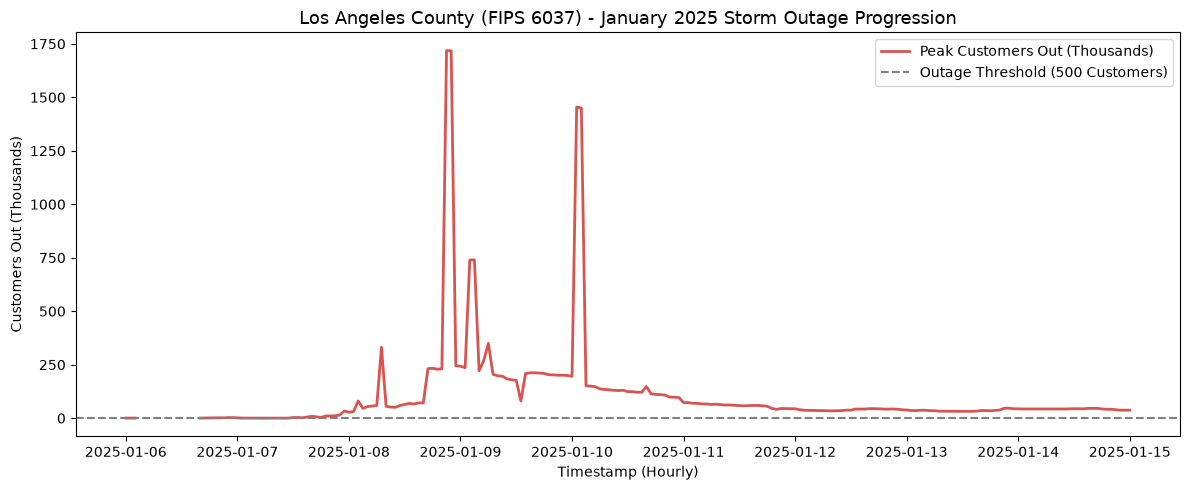

In [ ]:
# Filter for Los Angeles County (FIPS 6037) during the January 2025 storm
la_storm = (
    df_hourly
    .filter(
        (pl.col("fips_code") == 6037) &
        (pl.col("hourly_timestamp") >= pl.datetime(2025, 1, 6)) &
        (pl.col("hourly_timestamp") <= pl.datetime(2025, 1, 15))
    )
    .sort("hourly_timestamp")
)

# Plot
plt.figure(figsize=(12, 5))
plt.plot(
    la_storm["hourly_timestamp"], 
    la_storm["customers_out_max"] / 1_000, 
    color="#d9534f", 
    linewidth=2,
    label="Peak Customers Out (Thousands)"
)
plt.axhline(0.5, color="gray", linestyle="--", label="Outage Threshold (500 Customers)")
plt.title("Los Angeles County (FIPS 6037) - January 2025 Storm Outage Progression", fontsize=13)
plt.xlabel("Timestamp (Hourly)")
plt.ylabel("Customers Out (Thousands)")
plt.legend()
plt.tight_layout()
plt.show()


# Part 3: Data insights

### First steps
A couple of basic things should be filtered out of the dataset before proceeding with it:  
1. FIPS codes should be converted to 5 char strings instead of integers
2. null outages should be removed as they are invalid
3. outages reported with negative values should be removed

In [74]:
print(f"Rows before cleaning: {len(df_hourly):,}")

Rows before cleaning: 8,874,464


In [75]:
clean_df = (
    df_hourly
    .with_columns([
        pl.col("fips_code").cast(pl.Utf8).str.zfill(5).alias("fips_code")
    ])
    .filter(
        pl.col("customers_out_max").is_not_null() &
        (pl.col("customers_out_max") >= 0)
    )
)

### Removing duplicates
In the event there are duplicate county-hour records, they should be removed.

In [77]:
duplicates = clean_df.filter(clean_df.select(["fips_code", "hourly_timestamp"]).is_duplicated())
print(f"Duplicate county-hour records found: {len(duplicates)}")

Duplicate county-hour records found: 0


### Overwrite parquet
Now we can overwrite the parquet we made with the updated, clean table.

In [76]:
clean_df.write_parquet(PROCESSED_PARQUET, compression="zstd")
print(f"Rows after cleaning:  {len(clean_df):,}")
print(f"Removed missing/corrupt rows: {len(df_hourly) - len(clean_df):,}")
clean_df.head(5)

Rows after cleaning:  8,262,051
Removed missing/corrupt rows: 612,413


fips_code,hourly_timestamp,customers_out_max,county,state,intervals_reported,is_outage_500
str,datetime[μs],i64,str,str,u32,i8
"""01001""",2025-01-01 00:00:00,7,"""Autauga""","""Alabama""",4,0
"""01001""",2025-01-01 01:00:00,13,"""Autauga""","""Alabama""",4,0
"""01001""",2025-01-01 02:00:00,405,"""Autauga""","""Alabama""",4,0
"""01001""",2025-01-01 03:00:00,7,"""Autauga""","""Alabama""",4,0
"""01001""",2025-01-01 04:00:00,7,"""Autauga""","""Alabama""",3,0
